# KIPS MMPA Analysis

**Author:** Benjamin Stickland  
**Affiliation:** UNC Chapel Hill
**Date:** 2026

In [1]:
import os
import warnings
import subprocess
import sys
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import seaborn as sns
from tqdm import tqdm

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image as PILImage

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Input Path

In [2]:
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'Data').is_dir() else Path.cwd().parent
DATA_DIR = str(PROJECT_DIR / 'Data')
KIPS_CURATED_CSV = str(PROJECT_DIR / 'Output' / 'Intermediate' / 'KIPS_Curated' / 'KIPS_Curated_SI65.csv')

# Output Path

In [3]:
OUTPUT_ROOT = PROJECT_DIR / 'Output'
MMPA_WORK_DIR = OUTPUT_ROOT / 'Intermediate' / 'MMPA'
DATA_TABLES_DIR = OUTPUT_ROOT / 'Tables' / 'Supplementary_Data'
MAIN_FIGURES_DIR = OUTPUT_ROOT / 'Figures' / 'Main'
for folder in (MMPA_WORK_DIR, DATA_TABLES_DIR, MAIN_FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Parameters

In [4]:
SELECTIVITY_COLUMN     = 'SI65'
NUM_CUTS               = 1
MIN_PAIRS              = 2
TOP_N_BAR              = 10
TOP_N_BOX              = 6
EXEMPLAR_ABS_THRESHOLD = 0.20
EXEMPLAR_MAX_PAIRS     = 5
SIGNIFICANCE_PERCENTILE = 90

# Plotting

In [5]:
plt.rcParams.update({
    'font.size': 7,
    'font.family': 'Arial',
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'axes.titlesize': 7,
    'figure.dpi': 450,
    'savefig.dpi': 450,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Utility Functions

In [6]:
# SMILES canonicalization
def get_canonical_smiles(smi):
    if not smi:
        return None
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    return Chem.MolToSmiles(m, canonical=True)

# Change in heavy atom between SMILES
def calculate_delta_heavy_atoms(from_smi, to_smi):
    fm = Chem.MolFromSmiles(from_smi)
    tm = Chem.MolFromSmiles(to_smi)
    if fm is None or tm is None:
        return 0
    return Descriptors.HeavyAtomCount(tm) - Descriptors.HeavyAtomCount(fm)

def exact_match(smiles, patt_mol):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or patt_mol is None:
        return False
    m = mol.GetSubstructMatch(patt_mol)
    return bool(m) and (len(m) == mol.GetNumAtoms())

def exact_match_any(smiles, patterns):
    return any(exact_match(smiles, p) for p in patterns)

# Transformation Rule Dictionary

In [7]:
HALOGEN = ['[*:1]F', '[*:1]Cl', '[*:1]Br', '[*:1]I']

GROUPS = {
    'Hydrogen': ['[*:1][H]'],
    'Methyl': ['[*:1][CH3]'],
    'OMe': ['[*:1][OX2][CH3]'],
    'OH': ['[*:1][OX2H]'],
    'NH2': ['[*:1][NX3H2]'],
    'Halide': HALOGEN,
    'CF3': ['[*:1]C(F)(F)F'],
    'cPr': ['[*:1]C1CC1'],
    'Nitrile': ['[*:1]C#N'],
    'Sulfonamide': ['[*:1]S(=O)(=O)N'],
    'Sulfonyl': ['[*:1]S(=O)(=O)C'],
    'Acetyl': ['[*:1]C(=O)C'],
    'Amide': ['[*:1]C(=O)N'],
    'Ethyl': ['[*:1][CH2][CH3]'],
    'iPr': ['[*:1]C([CH3])[CH3]'],
    'tBu': ['[*:1]C([CH3])([CH3])[CH3]']
}

ALL_NAMES = [
    'Hydrogen', 'Methyl', 'OMe', 'OH', 'NH2', 'Halide', 'CF3', 'cPr',
    'Nitrile', 'Sulfonamide', 'Sulfonyl', 'Acetyl', 'Amide',
    'Ethyl', 'iPr', 'tBu'
]

# Dictionary of all group pair patterns
def build_transformation_rules():
    def canonical_pair_name(a, b):
        if a == b:
            return None
        # Hydrogen as the 'left' side
        if a == 'Hydrogen' or b == 'Hydrogen':
            left = 'Hydrogen'
            right = b if a == 'Hydrogen' else a
            return f'{left}<->{right}'
        left, right = sorted([a, b])
        return f'{left}<->{right}'

    pairs_seen = set()
    rules = {}
    
    for i, a in enumerate(ALL_NAMES):
        for b in ALL_NAMES[i+1:]:
            key = frozenset([a, b])
            if key in pairs_seen:
                continue
            pairs_seen.add(key)
            label = canonical_pair_name(a, b)
            if label:
                rules[label] = (GROUPS[a], GROUPS[b])
    
    # Halogen-to-halogen special case
    rules['Halogen Exchange'] = (GROUPS['Halide'], GROUPS['Halide'])
    
    compiled = {
        label: ([Chem.MolFromSmarts(s) for s in pair[0]], [Chem.MolFromSmarts(s) for s in pair[1]],)
        for label, pair in rules.items()
    }
    
    return compiled

COMPILED_RULES = build_transformation_rules()
print(f"Generated {len(COMPILED_RULES)} transformation rules")

Generated 121 transformation rules


# Transformation Utility Functions

In [8]:
# Specific Halogen check
def halogen_symbol_present(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    for sym in ['F', 'Cl', 'Br', 'I']:
        patt = Chem.MolFromSmarts(f'[*:1]{sym}')
        if exact_match(smiles, patt):
            return sym
    return None

# Characterization
def categorize_exact(from_frag, to_frag):
    if not from_frag or not to_frag:
        return "Uncategorized"
    if exact_match_any(from_frag, [Chem.MolFromSmarts(s) for s in HALOGEN]) and \
       exact_match_any(to_frag, [Chem.MolFromSmarts(s) for s in HALOGEN]):
        s1 = halogen_symbol_present(from_frag)
        s2 = halogen_symbol_present(to_frag)
        if s1 and s2 and s1 != s2:
            return "Halogen Exchange"
    for label, (from_patts, to_patts) in COMPILED_RULES.items():
        if label == "Halogen Exchange":
            continue
        # Check for match in either direction
        fwd = exact_match_any(from_frag, from_patts) and exact_match_any(to_frag, to_patts)
        rev = exact_match_any(from_frag, to_patts) and exact_match_any(to_frag, from_patts)
        if fwd or rev:
            return label
    return "Uncategorized"

# Element that corresponds to attachment in fragement
def get_anchor_element(fragment_smarts, host_smiles):
    patt = Chem.MolFromSmarts(fragment_smarts)
    host = Chem.MolFromSmiles(host_smiles)
    if patt is None or host is None:
        return None
    anchor_idx = None
    for atom in patt.GetAtoms():
        if atom.GetAtomMapNum() == 1:
            anchor_idx = atom.GetIdx()
            break
    if anchor_idx is None:
        return None
    matches = host.GetSubstructMatches(patt, uniquify=True)
    if not matches:
        return None
    host_anchor_idx = matches[0][anchor_idx]
    return host.GetAtomWithIdx(host_anchor_idx).GetSymbol()

# Check for N-methylation vs methylation
def refine_methylation_labels(transforms):
    out = transforms['category_exact'].copy()
    mask = transforms['category_exact'] == 'Hydrogen<->Methyl'
    if not mask.any():
        return out
    for idx, row in tqdm(transforms[mask].iterrows(), total=mask.sum()):
        anchor = get_anchor_element(row['from_fragment'], row['source_smiles'])
        if anchor is None:
            anchor = get_anchor_element(row['to_fragment'], row['product_smiles'])
        if anchor == 'N':
            out.at[idx] = 'N-methylation'
    return out

# MMPDB-lib Wrapper

In [9]:
class MMPAAnalyzer:
    def __init__(self, output_dir):
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.mmpdb_cmd = [sys.executable, '-m', 'mmpdblib']
        self.fragdb_file = self.output_dir / "Fragments.fragdb"
        self.mmpdb_file = self.output_dir / "MMPs.mmpdb"

    # Prepares .smi file
    def prepare_smiles_file(self, df, smiles_col='SMILES', id_col='Compound ID'):
        smi_file = self.output_dir / "Compounds.smi"
        df[[smiles_col, id_col]].to_csv(smi_file, sep='\t', header=False, index=False)
        return str(smi_file)

    # Prepares .tsv properties file
    def prepare_properties_file(self, df, property_cols, id_col='Compound ID'):
        props_file = self.output_dir / "Properties.tsv"
        props_df = df[[id_col] + property_cols].copy()
        props_df.columns = ['ID'] + property_cols
        props_df.to_csv(props_file, sep='\t', index=False)
        return str(props_file)

    # MMPDB-lib fragmentation
    def fragment_structures(self, smi_file, num_cuts=1):
        cmd = self.mmpdb_cmd + [
            'fragment', smi_file, 
            '--output', str(self.fragdb_file), 
            '--num-cuts', str(num_cuts)
        ]
        subprocess.run(cmd, capture_output=True, text=True, check=True)

    # MMPDB-lib indexing
    def index_fragments(self, properties_file=None):
        cmd = self.mmpdb_cmd + [
            'index', str(self.fragdb_file), 
            '--output', str(self.mmpdb_file)
        ]
        if properties_file:
            cmd.extend(['--properties', properties_file])
        subprocess.run(cmd, capture_output=True, text=True, check=True)

    # MMPDB-lib transform
    def analyze_transformations(self, df, property_col, min_pairs=2):
        results = []
        for _, row in tqdm(df.iterrows(), total=len(df), desc="Analyzing transformations"):
            cmd = self.mmpdb_cmd + [
                'transform',
                '--smiles', row['SMILES'],
                str(self.mmpdb_file),
                '--property', property_col,
                '--min-pairs', str(min_pairs)
            ]
            result = subprocess.run(cmd, capture_output=True, text=True)
            
            if result.returncode != 0 or not result.stdout:
                continue
            
            for trans in self._parse_transform_output(result.stdout):
                trans.update({
                    'source_smiles': row['SMILES'],
                    'source_id': row['Compound ID'],
                    'source_selectivity': row[property_col]
                })
                results.append(trans)
        return pd.DataFrame(results)

    # Parse output from MMPDB-lib transform
    def _parse_transform_output(self, output):
        lines = output.strip().split('\n')
        header_idx = next((i for i, line in enumerate(lines) if line.startswith("ID\tSMILES")), -1)
            
        if header_idx == -1:
            return []
        
        parsed = []
        for line in lines[header_idx + 1:]:
            cols = line.split('\t')
            if len(cols) < 4:
                continue
            parsed.append(dict(zip(['id', 'product_smiles', 'from_fragment', 'to_fragment'], cols[:4])))
        return parsed

# Load and Pre-Process Dataset

In [10]:
# Load dataset
raw_df = pd.read_csv(KIPS_CURATED_CSV)

# Convert name
raw_df = raw_df.rename(columns={'SMILES_standardized': 'SMILES'})

# Canonicalize SMILES
raw_df['SMILES'] = raw_df['SMILES'].apply(get_canonical_smiles)

# Drop invalid SMILES
raw_df.dropna(subset=['SMILES'], inplace=True)

# Keep only first occurance of duplicate if present
raw_df.drop_duplicates(subset=['SMILES'], keep='first', inplace=True)

# Remove space from Compound ID header for MMPDB-lib
raw_df['Compound ID'] = raw_df['Compound ID'].astype(str).str.replace(' ', '_', regex=False)

raw_df.reset_index(drop=True, inplace=True)
df = raw_df.copy()

print(f"Loaded & prepared {len(df)} unique compounds")

Loaded & prepared 1538 unique compounds


# MMPA Fragmentation

In [11]:
#Initialize
analyzer = MMPAAnalyzer(output_dir=MMPA_WORK_DIR)

# SMILES File Generation
smi_file = analyzer.prepare_smiles_file(df, smiles_col='SMILES', id_col='Compound ID')

# TSV File Generation
props_file = analyzer.prepare_properties_file(df, [SELECTIVITY_COLUMN], id_col='Compound ID')

# Fragmentation
analyzer.fragment_structures(smi_file, num_cuts=NUM_CUTS)

# Indexing
analyzer.index_fragments(props_file)

print("Fragmentation and indexing complete")

Fragmentation and indexing complete


# MMPA Transformation Analysis

In [12]:
raw_transforms_df = analyzer.analyze_transformations(df, property_col=SELECTIVITY_COLUMN, min_pairs=MIN_PAIRS)

print(f"Found {len(raw_transforms_df)} raw transformation records.")

Analyzing transformations: 100%|██████████| 1538/1538 [15:09<00:00,  1.69it/s]

Found 59207 raw transformation records.


# MMPA Post-Processing Transformations

In [13]:
transforms = raw_transforms_df.copy()

# Canonicalize SMILES
transforms['product_smiles'] = transforms['product_smiles'].apply(get_canonical_smiles)
transforms['source_smiles'] = transforms['source_smiles'].apply(get_canonical_smiles)

# Map properties using the more reliable Compound ID
id_lookup = df.set_index('SMILES')[SELECTIVITY_COLUMN]
transforms['product_selectivity'] = transforms['product_smiles'].map(id_lookup)
transforms.dropna(subset=['product_selectivity'], inplace=True)

# Calculate key deltas
transforms['delta_selectivity'] = transforms['product_selectivity'] - transforms['source_selectivity']
transforms['delta_heavy_atoms'] = transforms.apply(lambda r: calculate_delta_heavy_atoms(r['from_fragment'], r['to_fragment']), axis=1)

processed_transforms_df = transforms.copy()
print(f"Retained {len(transforms)} transformations")

Retained 1534 transformations


# MMPA Post-Processing Categorization

In [14]:
processed_transforms_df['category_exact'] = processed_transforms_df.apply(lambda r: categorize_exact(r['from_fragment'], r['to_fragment']), axis=1)

# Special N-methylations
processed_transforms_df['category_exact'] = refine_methylation_labels(processed_transforms_df)

categorized_transforms_df = processed_transforms_df.copy()
print("Categorization complete")

100%|██████████| 73/73 [00:00<00:00, 2567.75it/s]

Categorization complete


# MMPA Post-Processing Deduplication & Summarization

In [15]:
transforms = categorized_transforms_df.copy()

# Create a unique key for each AB pair
transforms['pair_key'] = transforms.apply(lambda r: '||'.join(sorted([r['source_smiles'], r['product_smiles']])), axis=1)

# Keep largest-magnitude change for any AB pair to avoid double-counting
transforms = (transforms.sort_values(by='delta_selectivity', key=lambda s: s.abs(), ascending=False).drop_duplicates(subset='pair_key', keep='first').reset_index(drop=True))

summary = transforms[transforms['category_exact'] != 'Uncategorized'].copy()

def pct_signif(x):
    return (np.abs(x) >= significance_threshold).mean() * 100.0

summary_df = summary.groupby('category_exact').agg(
    total_pairs=('delta_selectivity', 'size'),
    avg_delta=('delta_selectivity', 'mean'),
    median_delta=('delta_selectivity', 'median'),
    mean_abs_delta=('delta_selectivity', lambda x: np.mean(np.abs(x))),
    median_abs_delta=('delta_selectivity', lambda x: np.median(np.abs(x))),
    std_delta=('delta_selectivity', 'std'),
    unique_transformations=('pair_key', 'nunique')
).reset_index().rename(columns={'category_exact': 'transformation_type'})

summary_df = summary_df.sort_values('total_pairs', ascending=False)

transforms[['id', 'product_smiles', 'from_fragment', 'to_fragment', 'source_smiles', 'source_selectivity', 'product_selectivity', 'delta_selectivity', 'category_exact']].set_axis(
    ['ID', 'Product SMILES', 'Fragment (Source)', 'Fragment (Product)', 'Source SMILES', 'Selectivity (Source)', 'Selectivity (Product)', 'Selectivity (Delta)', 'Category'], axis=1
).to_csv(DATA_TABLES_DIR / 'Supplementary_Data_Table_8_Matched_Pairs.csv', index=False, float_format='%.3f', encoding='utf-8-sig')
summary_df.drop(columns='unique_transformations').set_axis(
    ['Transformation', 'Total Pairs', 'Delta (Average)', 'Delta (Median)', 'Abs Delta (Mean)', 'Abs Delta (Median)', 'Delta (Std)'], axis=1
).to_csv(DATA_TABLES_DIR / 'Supplementary_Data_Table_7_MMPA_Summary.csv', index=False, float_format='%.3f', encoding='utf-8-sig')

transforms_df = transforms.copy()

print(f"Total unique transformation pairs: {len(transforms_df)}")
print(f"Transformation categories found: {summary_df['transformation_type'].nunique()}")

Total unique transformation pairs: 846
Transformation categories found: 39


# MMPA Plot

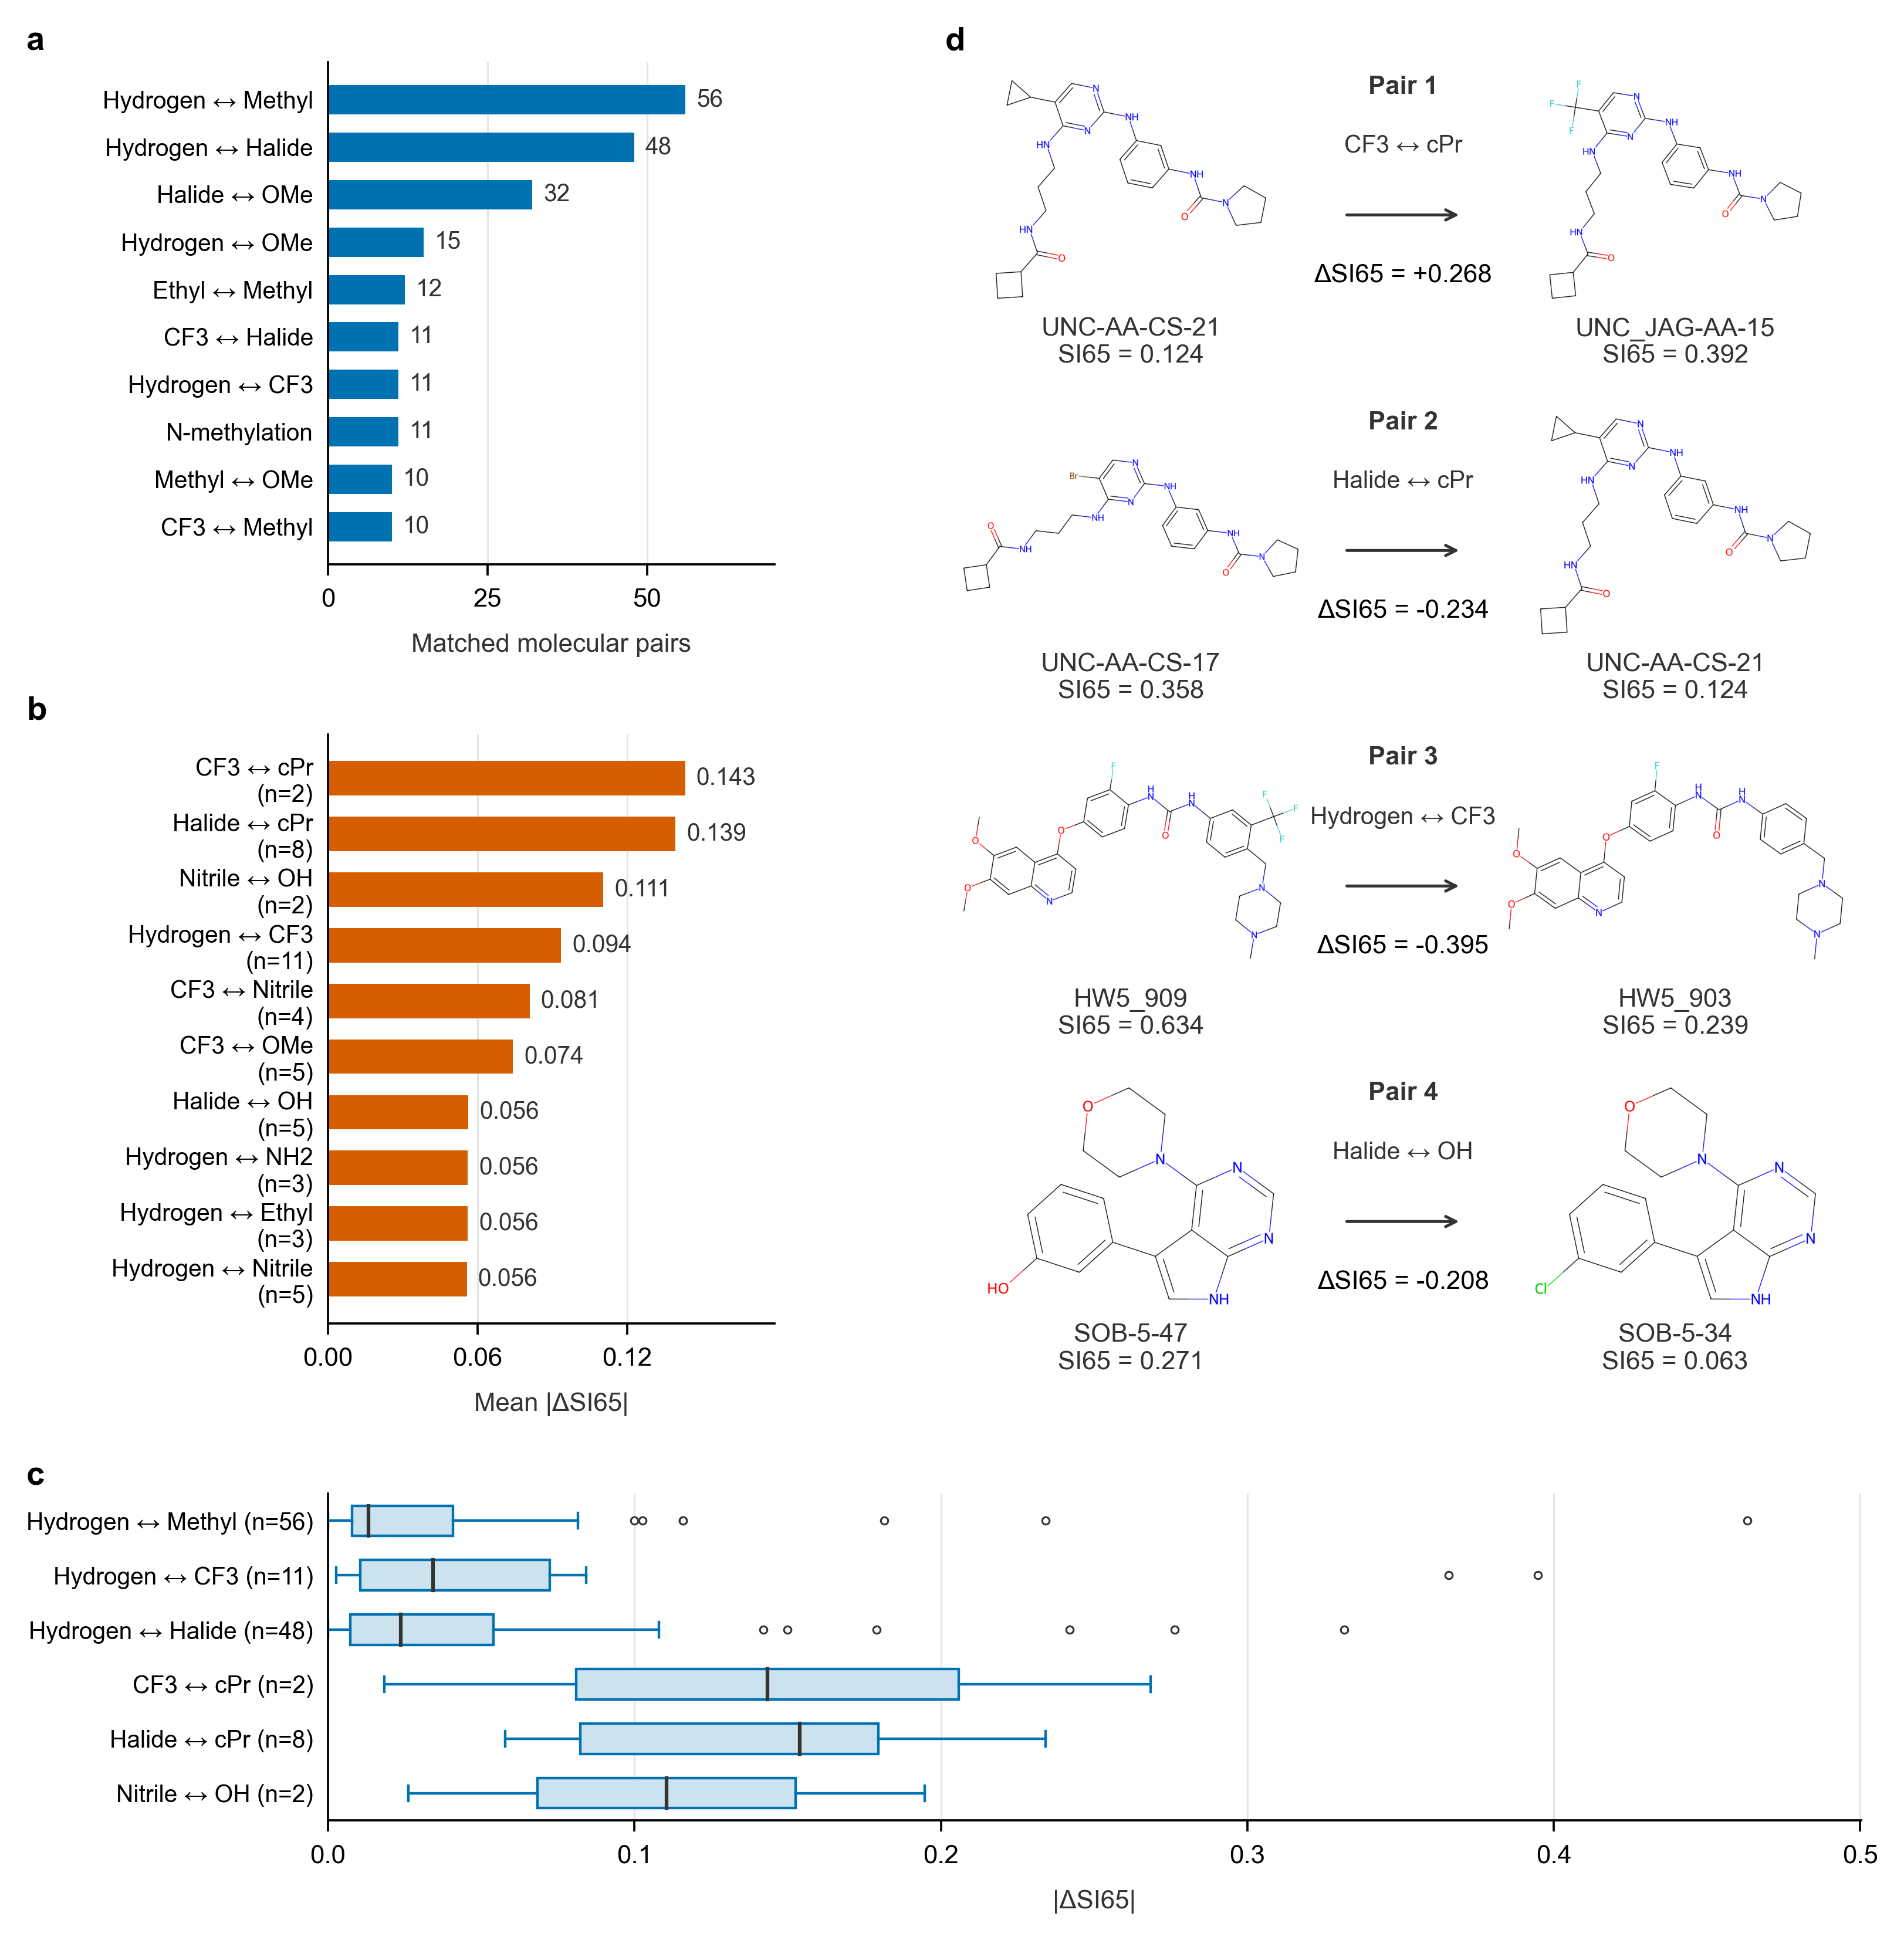

In [16]:
def pick_exemplars(transforms, summary, abs_threshold, max_pairs):
    exemplars = []
    for t in summary.nlargest(10, 'mean_abs_delta')['transformation_type']:
        sub = transforms[transforms['category_exact'] == t].copy()
        sub['abs_delta'] = sub['delta_selectivity'].abs()
        hits = sub[sub['abs_delta'] >= abs_threshold].sort_values('abs_delta', ascending=False)
        if not hits.empty:
            exemplars.append(hits.iloc[0])
        if len(exemplars) >= max_pairs:
            break
    return exemplars
    
exemplars = pick_exemplars(transforms_df, summary_df, EXEMPLAR_ABS_THRESHOLD, EXEMPLAR_MAX_PAIRS)

compound_labels = pd.read_csv(
    KIPS_CURATED_CSV, usecols=lambda c: c in {'Compound ID', 'SMILES', 'SMILES_standardized'}
)
name_smiles_column = 'SMILES_standardized' if 'SMILES_standardized' in compound_labels else 'SMILES'
compound_labels['SMILES'] = compound_labels[name_smiles_column].apply(get_canonical_smiles)
compound_names = (compound_labels.dropna(subset=['SMILES']).drop_duplicates('SMILES')
                  .set_index('SMILES')['Compound ID'])

def plot_mmpa(transforms, summary, example_pairs, compound_names):
    import textwrap
    from matplotlib.ticker import MaxNLocator

    blue, orange, charcoal = '#0072B2', '#D55E00', '#333333'
    label = lambda name: textwrap.fill(name.replace('<->', ' \u2194 '), width=22)
    n_examples = len(example_pairs)
    with plt.rc_context({
        'font.family': 'Arial', 'font.size': 7, 'axes.labelsize': 7,
        'axes.titlesize': 7, 'xtick.labelsize': 7, 'ytick.labelsize': 6.5,
        'axes.linewidth': 0.6, 'text.color': charcoal, 'axes.labelcolor': charcoal,
        'figure.dpi': 450, 'savefig.dpi': 450, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    }):
        figure = plt.figure(figsize=(7.08, max(7.4, 2.0 + 1.25 * n_examples)), facecolor='white')
        grid = figure.add_gridspec(
            3, 2, left=.17, right=.99, bottom=.075, top=.975,
            width_ratios=[1, 2.05], height_ratios=[2.3, 2.7, 1.5],
            hspace=.36, wspace=.25,
        )
        ax_a = figure.add_subplot(grid[0, 0])
        ax_b = figure.add_subplot(grid[1, 0])
        ax_c = figure.add_subplot(grid[2, :])
        for ax in (ax_a, ax_b, ax_c):
            ax.spines[['top', 'right']].set_visible(False)
            ax.tick_params(axis='y', length=0, pad=4)
            ax.tick_params(axis='x', length=3, width=.6)
            ax.set_axisbelow(True)
            ax.grid(axis='x', color='#e5e5e5', linewidth=.5)

        common = summary.nlargest(TOP_N_BAR, 'total_pairs')
        impactful = summary.nlargest(TOP_N_BAR, 'mean_abs_delta')
        for ax, data, field, color, xlabel in [
            (ax_a, common, 'total_pairs', blue, 'Matched molecular pairs'),
            (ax_b, impactful, 'mean_abs_delta', orange,
             f'Mean |\u0394{SELECTIVITY_COLUMN}|'),
        ]:
            positions = np.arange(len(data))
            bars = ax.barh(positions, data[field], height=.62, color=color, linewidth=0)
            names = [label(t) for t in data['transformation_type']]
            if field == 'mean_abs_delta':
                names = [f'{name}\n(n={int(n)})' for name, n in zip(names, data['total_pairs'])]
            ax.set_yticks(positions, names)
            ax.invert_yaxis()
            ax.set_xlim(0, max(float(data[field].max()) * 1.25, .01))
            ax.bar_label(bars, fmt='%.0f' if field == 'total_pairs' else '%.3f', padding=3, fontsize=6.5)
            ax.set_xlabel(xlabel, labelpad=6)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=field == 'total_pairs'))

        candidates = pd.concat([
            summary.nlargest(TOP_N_BOX, 'total_pairs')['transformation_type'],
            summary.nlargest(TOP_N_BOX, 'mean_abs_delta')['transformation_type'],
        ]).unique()
        distributions = transforms[transforms['category_exact'].isin(candidates)].copy()
        distributions['abs_delta'] = distributions['delta_selectivity'].abs()
        categories = (distributions.groupby('category_exact')['abs_delta'].max()
                      .reindex(candidates).dropna().sort_values(ascending=False)
                      .index.tolist()[:TOP_N_BOX])
        values = [distributions.loc[distributions['category_exact'].eq(t), 'abs_delta'].dropna()
                  for t in categories]
        ax_c.boxplot(
            values, vert=False, widths=.55, patch_artist=True, whis=1.5,
            boxprops=dict(facecolor='#cce3ef', edgecolor=blue, linewidth=.7),
            medianprops=dict(color=charcoal, linewidth=1),
            whiskerprops=dict(color=blue, linewidth=.7), capprops=dict(color=blue, linewidth=.7),
            flierprops=dict(marker='o', markersize=2, markerfacecolor='white',
                            markeredgecolor=charcoal, markeredgewidth=.5),
        )
        ax_c.set_yticks(np.arange(1, len(categories) + 1),
                       [f'{label(t)} (n={len(v)})' for t, v in zip(categories, values)])
        ax_c.invert_yaxis()
        ax_c.set_xlim(0, max(.1, 1.08 * max(v.max() for v in values)))
        ax_c.set_xlabel(f'|\u0394{SELECTIVITY_COLUMN}|', labelpad=6)

        panel_d = figure.add_subplot(grid[:2, 1])
        panel_d.axis('off')
        if n_examples:
            structures = grid[:2, 1].subgridspec(n_examples, 3, width_ratios=[2, .9, 2],
                                               hspace=.32, wspace=.01)
            for i, pair in enumerate(example_pairs):
                for col, side in ((0, 'source'), (2, 'product')):
                    ax = figure.add_subplot(structures[i, col])
                    smiles = get_canonical_smiles(pair[f'{side}_smiles'])
                    compound_name = textwrap.fill(str(compound_names.loc[smiles]), width=20, break_long_words=False)
                    mol = Chem.MolFromSmiles(smiles)
                    if mol is not None:
                        ax.imshow(Draw.MolToImage(mol, size=(1000, 650)))
                    ax.axis('off')
                    ax.text(.5, -.03, f'{compound_name}\nSI65 = {pair[f"{side}_selectivity"]:.3f}',
                            transform=ax.transAxes, ha='center', va='top', fontsize=7)
                center = figure.add_subplot(structures[i, 1])
                center.axis('off')
                center.text(.5, .95, f'Pair {i + 1}', ha='center', va='top', fontsize=7, fontweight='bold')
                center.text(.5, .67, label(pair['category_exact']), ha='center', va='center', fontsize=6.5)
                center.annotate('', xy=(.88, .40), xytext=(.12, .40), xycoords='axes fraction',
                                arrowprops=dict(arrowstyle='->', linewidth=.8, color=charcoal))
                delta = pair['delta_selectivity']
                center.text(.5, .16, f'\u0394SI65 = {delta:+.3f}', ha='center', va='center',
                            fontsize=7, color='black')
        else:
            panel_d.text(.5, .5, 'No exemplar pairs meet the selection threshold.', ha='center')

        # Align a/b/c with the left edge of panel c's tick labels.
        figure.canvas.draw()
        renderer = figure.canvas.get_renderer()
        label_left = min(tick.get_window_extent(renderer).x0
                         for tick in ax_c.get_yticklabels() if tick.get_visible())
        label_x = figure.transFigure.inverted().transform((label_left, 0))[0]
        for ax, letter in ((ax_a, 'a'), (ax_b, 'b'), (ax_c, 'c'), (panel_d, 'd')):
            anchor_ax = ax_a if ax is panel_d else ax
            label_y = figure.transFigure.inverted().transform(
                anchor_ax.transAxes.transform((0, 1.025)))[1]
            figure.text(panel_d.get_position().x0 if ax is panel_d else label_x,
                        label_y, letter, fontsize=9, fontweight='bold',
                        ha='left', va='baseline', color='black')

        for extension in ('pdf', 'png'):
            figure.savefig(MAIN_FIGURES_DIR / f'Figure_6_MMPA.{extension}', bbox_inches='tight')
    return figure

fig_mmpa = plot_mmpa(transforms_df, summary_df, exemplars, compound_names)
plt.show()


In [17]:
profile_df = pd.read_csv(Path(DATA_DIR) / 'KIPS_Dataset.csv')
smiles_col = 'SMILES_standardized' if 'SMILES_standardized' in profile_df else 'SMILES'
profile_df['SMILES'] = profile_df[smiles_col].apply(get_canonical_smiles)
metadata_cols = {
    'Compound ID', 'SMILES', 'SMILES_standardized', 'mol_std', 'InChI_Key',
    'SI50', 'SI65', 'SI90', 'GINI', 'is_promiscuous',
}
kinase_cols = [c for c in profile_df if c not in metadata_cols and '-' not in c]
profile_lookup = (
    profile_df.dropna(subset=['SMILES']).drop_duplicates('SMILES')
    .set_index('SMILES')[kinase_cols]
    .apply(pd.to_numeric, errors='coerce').clip(lower=0, upper=100)
)

pair_rows = []
for pair_number, pair in enumerate(exemplars, start=1):
    for smiles_key, si_key in (('source_smiles', 'source_selectivity'),
                               ('product_smiles', 'product_selectivity')):
        smiles = get_canonical_smiles(pair[smiles_key])
        pair_rows.append({
            'Pair': f'Pair {pair_number}',
            'Change': pair['category_exact'].replace('<->', ' - '),
            'SI(65)': pair[si_key],
            'SMILES': smiles,
            **profile_lookup.loc[smiles].to_dict(),
        })

pair_kinase_df = pd.DataFrame(pair_rows, columns=['Pair', 'Change', 'SI(65)', 'SMILES', *kinase_cols])
pair_kinase_df.rename(columns={'SI(65)': 'SI65'}).assign(SI65=pair_kinase_df['SI(65)'].map('{:.3f}'.format)).to_csv(
    DATA_TABLES_DIR / 'Supplementary_Data_Table_9_Exemplar_Profiles.csv', index=False, float_format='%.1f', encoding='utf-8-sig')
